# 02 churn model



In [1]:
from IPython.display import display
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 42

# Locate the project from its root or a subdirectory such as notebooks.
project_dir = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed" / "customer_master.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Open this notebook from the project root or its notebooks folder. "
        "The project must contain data/processed/customer_master.csv."
    )
print("Project directory:", project_dir)


data_path = project_dir / "data" / "processed" / "customer_master.csv"

df = pd.read_csv(
    data_path,
    dtype={"customer_id": "string"},
    na_values=["NULL"]
)

assert df["customer_id"].notna().all(), "Missing customer IDs found."
assert df["customer_id"].is_unique, "Duplicate customer IDs found."
assert df["churn"].isin(["Yes", "No"]).all(), "Invalid churn labels found."

print("pandas version:", pd.__version__)
print("scikit-learn version:", sklearn.__version__)
print("Dataset shape:", df.shape)
print("Missing total charges:", df["total_charges"].isna().sum())

print("\nChurn distribution:")
print(df["churn"].value_counts())

display(df.head())

Project directory: C:\Users\21129\Desktop\硕士申请材料\telecom-churn-retention-analysis
pandas version: 3.0.3
scikit-learn version: 1.9.0
Dataset shape: (7043, 21)
Missing total charges: 11

Churn distribution:
churn
No     5174
Yes    1869
Name: count, dtype: int64


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,0002-ORFBO,Female,0,Yes,Yes,9,Yes,No,DSL,No,...,No,Yes,Yes,No,One year,Yes,Mailed check,65.6,593.30,No
1,0003-MKNFE,Male,0,No,No,9,Yes,Yes,DSL,No,...,No,No,No,Yes,Month-to-month,No,Mailed check,59.9,542.40,No
2,0004-TLHLJ,Male,0,No,No,4,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,73.9,280.85,Yes
3,0011-IGKFF,Male,1,Yes,No,13,Yes,No,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,98.0,1237.85,Yes
4,0013-EXCHZ,Female,1,Yes,No,3,Yes,No,Fiber optic,No,...,No,Yes,Yes,No,Month-to-month,Yes,Mailed check,83.9,267.40,Yes


In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["customer_id", "churn", "churn_flag"], errors="ignore")
y = df["churn"].map({"No": 0, "Yes": 1}).astype(int)

train_idx, holdout_idx = train_test_split(
    df.index,
    test_size=0.40,
    stratify=y,
    random_state=RANDOM_STATE
)

valid_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=0.50,
    stratify=y.loc[holdout_idx],
    random_state=RANDOM_STATE
)

X_train = X.loc[train_idx].copy()
X_valid = X.loc[valid_idx].copy()
X_test = X.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_valid = y.loc[valid_idx].copy()
y_test = y.loc[test_idx].copy()

assert set(train_idx).isdisjoint(valid_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(valid_idx).isdisjoint(test_idx)
assert len(train_idx) + len(valid_idx) + len(test_idx) == len(df)

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "customer_count": len(target),
            "churned_count": int(target.sum()),
            "churn_rate": target.mean()
        }
        for name, target in [
            ("Train", y_train),
            ("Validation", y_valid),
            ("Test", y_test)
        ]
    ]
)

display(
    split_summary.style.format({
        "customer_count": "{:,}",
        "churned_count": "{:,}",
        "churn_rate": "{:.2%}"
    })
)

print("Number of features:", X_train.shape[1])
print("Split overlap check: passed")

,split,customer_count,churned_count,churn_rate
0,Train,"4,225","1,121",26.53%
1,Validation,"1,409",374,26.54%
2,Test,"1,409",374,26.54%


Number of features: 19
Split overlap check: passed


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "tenure_months",
    "monthly_charges",
    "total_charges"
]

categorical_features = [
    column
    for column in X_train.columns
    if column not in numeric_features
]

numeric_pipeline_lr = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

numeric_pipeline_rf = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

preprocessor_lr = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline_lr, numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ],
    remainder="drop"
)

preprocessor_rf = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline_rf, numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features
        )
    ],
    remainder="drop"
)

assert "customer_id" not in X_train.columns
assert "churn" not in X_train.columns
assert "churn_flag" not in X_train.columns

print("Numeric features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nPreprocessors defined. No fitting performed.")


Numeric features: 3
['tenure_months', 'monthly_charges', 'total_charges']

Categorical features: 16
['gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method']

Preprocessors defined. No fitting performed.


In [4]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss
)

models = {
    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor_lr)),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    max_iter=2000,
                    random_state=RANDOM_STATE
                )
            )
        ]
    ),
    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor_rf)),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=300,
                    max_depth=10,
                    min_samples_leaf=5,
                    max_features="sqrt",
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                )
            )
        ]
    )
}

validation_probabilities = {}
validation_results = []

for model_name, model in models.items():
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_valid)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    validation_probabilities[model_name] = probabilities

    validation_results.append({
        "model": model_name,
        "roc_auc": roc_auc_score(y_valid, probabilities),
        "average_precision": average_precision_score(
            y_valid, probabilities
        ),
        "precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "brier_score": brier_score_loss(
            y_valid, probabilities
        ),
        "flagged_customers": int(predictions.sum())
    })

    print(f"{model_name}: training completed")

validation_comparison = (
    pd.DataFrame(validation_results)
    .set_index("model")
)

display(
    validation_comparison.style.format({
        "roc_auc": "{:.4f}",
        "average_precision": "{:.4f}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1": "{:.4f}",
        "brier_score": "{:.4f}",
        "flagged_customers": "{:,}"
    })
)

print("\nEvaluation dataset: validation")
print("Classification threshold: 0.50")
print("Test set has not been used for model evaluation.")

Logistic Regression: training completed
Random Forest: training completed


,roc_auc,average_precision,precision,recall,f1,brier_score,flagged_customers
model,,,,,,,
Logistic Regression,0.8375,0.6506,62.26%,52.94%,0.5723,0.1393,318
Random Forest,0.8431,0.6577,62.75%,50.00%,0.5565,0.1369,298



Evaluation dataset: validation
Classification threshold: 0.50
Test set has not been used for model evaluation.


In [5]:
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_rows = []
actual = y_valid.to_numpy()

for model_name, probabilities in validation_probabilities.items():
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        true_positive = int(
            ((predictions == 1) & (actual == 1)).sum()
        )
        false_positive = int(
            ((predictions == 1) & (actual == 0)).sum()
        )
        false_negative = int(
            ((predictions == 0) & (actual == 1)).sum()
        )

        threshold_rows.append({
            "model": model_name,
            "threshold": threshold,
            "precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "f1": f1_score(
                actual, predictions, zero_division=0
            ),
            "flagged_customers": int(predictions.sum()),
            "flagged_share": predictions.mean(),
            "true_positive": true_positive,
            "false_positive": false_positive,
            "false_negative": false_negative
        })

threshold_comparison = pd.DataFrame(threshold_rows)

for model_name in models:
    print(f"\n{model_name}")

    model_thresholds = (
        threshold_comparison
        .loc[threshold_comparison["model"] == model_name]
        .drop(columns="model")
        .set_index("threshold")
    )

    display(
        model_thresholds.style.format({
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1": "{:.4f}",
            "flagged_customers": "{:,}",
            "flagged_share": "{:.2%}",
            "true_positive": "{:,}",
            "false_positive": "{:,}",
            "false_negative": "{:,}"
        })
    )


Logistic Regression


,precision,recall,f1,flagged_customers,flagged_share,true_positive,false_positive,false_negative
threshold,,,,,,,,
0.200000,46.06%,87.43%,0.6033,710,50.39%,327,383,47
0.250000,48.59%,82.89%,0.6126,638,45.28%,310,328,64
0.300000,51.90%,76.74%,0.6192,553,39.25%,287,266,87
0.350000,54.83%,71.39%,0.6202,487,34.56%,267,220,107
0.400000,57.24%,66.58%,0.6156,435,30.87%,249,186,125
0.450000,58.01%,59.09%,0.5854,381,27.04%,221,160,153
0.500000,62.26%,52.94%,0.5723,318,22.57%,198,120,176



Random Forest


,precision,recall,f1,flagged_customers,flagged_share,true_positive,false_positive,false_negative
threshold,,,,,,,,
0.200000,45.78%,88.50%,0.6035,723,51.31%,331,392,43
0.250000,48.83%,83.69%,0.6167,641,45.49%,313,328,61
0.300000,52.16%,77.54%,0.6237,556,39.46%,290,266,84
0.350000,55.74%,71.39%,0.6260,479,34.00%,267,212,107
0.400000,58.68%,64.17%,0.6130,409,29.03%,240,169,134
0.450000,61.58%,58.29%,0.5989,354,25.12%,218,136,156
0.500000,62.75%,50.00%,0.5565,298,21.15%,187,111,187


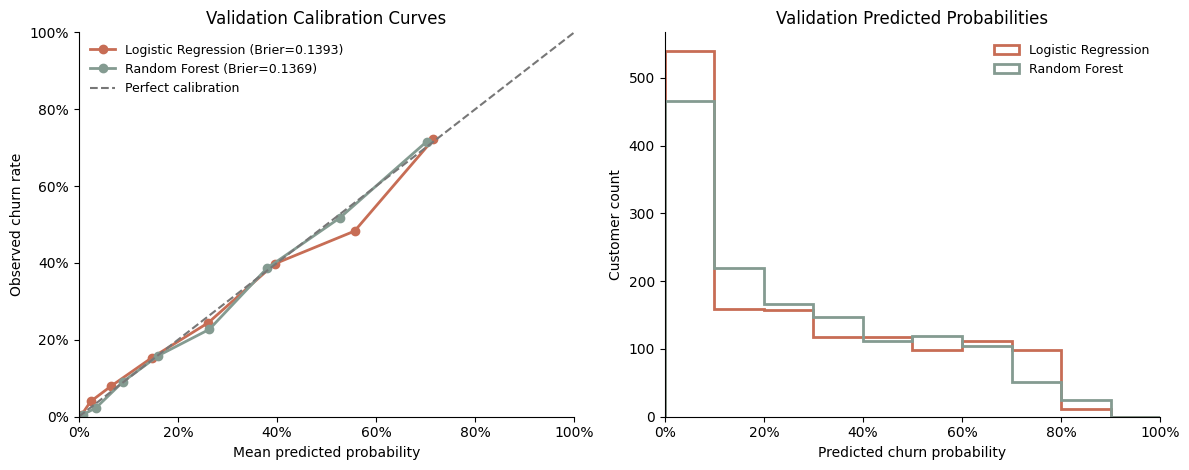

Provisional model: Random Forest
Working threshold: 0.35


In [6]:
from sklearn.calibration import calibration_curve
from matplotlib.ticker import PercentFormatter

selected_model_name = "Random Forest"
selected_threshold = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

colors = {
    "Logistic Regression": "#C76D55",
    "Random Forest": "#849B91"
}

for model_name, probabilities in validation_probabilities.items():
    observed_rate, mean_probability = calibration_curve(
        y_valid,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    brier = brier_score_loss(y_valid, probabilities)

    axes[0].plot(
        mean_probability,
        observed_rate,
        marker="o",
        linewidth=2,
        color=colors[model_name],
        label=f"{model_name} (Brier={brier:.4f})"
    )

    axes[1].hist(
        probabilities,
        bins=np.linspace(0, 1, 11),
        histtype="step",
        linewidth=2,
        color=colors[model_name],
        label=model_name
    )

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="#777777",
    label="Perfect calibration"
)

axes[0].set(
    title="Validation Calibration Curves",
    xlabel="Mean predicted probability",
    ylabel="Observed churn rate",
    xlim=(0, 1),
    ylim=(0, 1)
)
axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].legend(frameon=False, fontsize=9)

axes[1].set(
    title="Validation Predicted Probabilities",
    xlabel="Predicted churn probability",
    ylabel="Customer count",
    xlim=(0, 1)
)
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].legend(frameon=False, fontsize=9)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout()

image_dir = project_dir / "images"
image_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    image_dir / "09_validation_probability_quality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Provisional model:", selected_model_name)
print("Working threshold:", selected_threshold)

,threshold,roc_auc,average_precision,precision,recall,f1,brier_score,flagged_customers,flagged_share
model,,,,,,,,,
Random Forest,0.35,0.8422,0.6583,55.97%,68.98%,0.6180,0.1361,461,32.72%


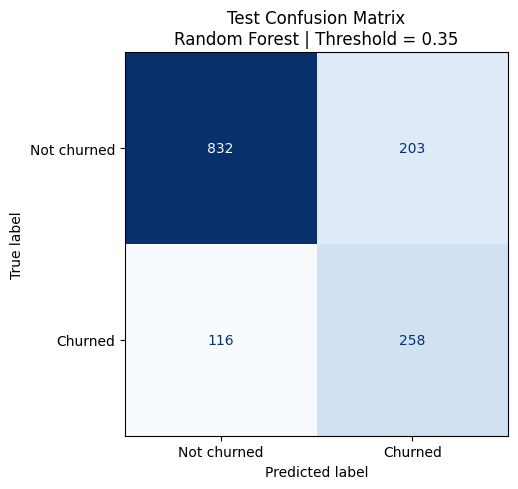

Correctly identified churned customers: 258
Missed churned customers: 116
False alarms: 203
Correctly identified non-churned customers: 832


In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

final_model = models[selected_model_name]
final_threshold = selected_threshold

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

test_results = pd.DataFrame(
    [{
        "model": selected_model_name,
        "threshold": final_threshold,
        "roc_auc": roc_auc_score(y_test, test_probabilities),
        "average_precision": average_precision_score(
            y_test, test_probabilities
        ),
        "precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_test, test_predictions, zero_division=0
        ),
        "brier_score": brier_score_loss(
            y_test, test_probabilities
        ),
        "flagged_customers": int(test_predictions.sum()),
        "flagged_share": test_predictions.mean()
    }]
).set_index("model")

display(
    test_results.style.format({
        "threshold": "{:.2f}",
        "roc_auc": "{:.4f}",
        "average_precision": "{:.4f}",
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1": "{:.4f}",
        "brier_score": "{:.4f}",
        "flagged_customers": "{:,}",
        "flagged_share": "{:.2%}"
    })
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not churned", "Churned"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    f"Test Confusion Matrix\n"
    f"{selected_model_name} | Threshold = {final_threshold:.2f}"
)

fig.tight_layout()

fig.savefig(
    image_dir / "10_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"Correctly identified churned customers: {tp:,}")
print(f"Missed churned customers: {fn:,}")
print(f"False alarms: {fp:,}")
print(f"Correctly identified non-churned customers: {tn:,}")

In [8]:
import json
import joblib

model_dir = project_dir / "models"
output_dir = project_dir / "data" / "processed"

model_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

validation_comparison.to_csv(
    output_dir / "model_validation_comparison.csv",
    index=True
)

threshold_comparison.to_csv(
    output_dir / "validation_threshold_comparison.csv",
    index=False
)

test_results.to_csv(
    output_dir / "model_test_results.csv",
    index=True
)

split_assignments = df[["customer_id"]].copy()
split_assignments["split"] = ""

for split_name, indices in [
    ("train", train_idx),
    ("validation", valid_idx),
    ("test", test_idx)
]:
    split_assignments.loc[indices, "split"] = split_name

assert split_assignments["split"].ne("").all()

split_assignments.to_csv(
    output_dir / "model_split_assignments.csv",
    index=False
)

test_prediction_output = df.loc[
    X_test.index,
    ["customer_id", "churn", "monthly_charges"]
].copy()

test_prediction_output["actual_churn"] = y_test
test_prediction_output["predicted_probability"] = test_probabilities
test_prediction_output["predicted_churn"] = test_predictions
test_prediction_output["split"] = "test"

test_prediction_output.to_csv(
    output_dir / "test_predictions.csv",
    index=False
)

joblib.dump(
    final_model,
    model_dir / "random_forest_pipeline.joblib"
)

metadata = {
    "model_name": selected_model_name,
    "threshold": float(final_threshold),
    "random_state": RANDOM_STATE,
    "training_rows": len(X_train),
    "validation_rows": len(X_valid),
    "test_rows": len(X_test),
    "feature_columns": X_train.columns.tolist(),
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "threshold_selection": (
        "Highest validation F1 among the evaluated model-threshold combinations."
    ),
    "training_scope": "Training split only; no refit after test evaluation.",
    "limitations": [
        "Full-dataset EDA preceded the split.",
        "Random split evaluation does not establish future-period performance.",
        "Predicted probabilities have no validated future time horizon.",
        "No observed retention intervention outcomes are available."
    ]
}

with open(
    model_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

print("Saved evaluation tables, split assignments, and test predictions.")
print("Saved model pipeline and metadata.")
print("Model directory:", model_dir)
print("Output directory:", output_dir)

Saved evaluation tables, split assignments, and test predictions.
Saved model pipeline and metadata.
Model directory: C:\Users\21129\Desktop\硕士申请材料\telecom-churn-retention-analysis\models
Output directory: C:\Users\21129\Desktop\硕士申请材料\telecom-churn-retention-analysis\data\processed


## Modeling Summary

### Approach
- Split 7,043 customers into training (60%), validation (20%), and test (20%) sets using stratified sampling and a fixed random seed.
- Excluded customer identifiers and target-derived fields from model inputs.
- Fitted preprocessing steps only on the training set through model pipelines.
- Compared Logistic Regression and Random Forest.
- Selected Random Forest with a threshold of 0.35 because it achieved the highest validation F1 among the evaluated model-threshold combinations.
- Validation calibration curves showed no clear systematic probability bias at the inspected bin level, so no additional calibration was applied.

### Test Results
- ROC-AUC: 0.8422
- Average Precision: 0.6583
- Precision: 55.97%
- Recall: 68.98%
- F1: 0.6180
- Brier Score: 0.1361

The model flagged 461 of 1,409 test customers (32.72%), identifying
258 of 374 observed churners (68.98%). The flagged group included
203 false positives, while 116 churners were missed.

### Business Interpretation
The model can support prioritization for a retention analysis.
However, a flagged customer is not a confirmed future churner,
and identifying churn does not demonstrate successful retention.

The threshold balances precision and recall through validation F1.
It has not been optimized for contact capacity, intervention cost,
or incremental profit.

### Limitations
- Full-dataset exploratory analysis preceded the split, so the test
  subset was not entirely unseen during project exploration.
- Random-split evaluation does not establish future-period performance.
- Calibration was inspected on validation data at an aggregate bin level;
  individual probability accuracy is not guaranteed.
- The dataset does not support a validated future prediction horizon.
- No intervention outcomes are available to estimate causal retention effects.
- Monthly charges are a value proxy, not profit or customer lifetime value.

### Next Step
Combine model scores with monthly charges to create illustrative
customer segments and retention ROI scenarios. Preserve split labels
to distinguish in-sample scores from held-out scores.